In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn as sk
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings("ignore")


In [2]:
# Load directly from the link shown in your second screenshot
url = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv'
df = pd.read_csv(url)
# Displaying the first few rows to verify
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

<Axes: xlabel='species', ylabel='count'>

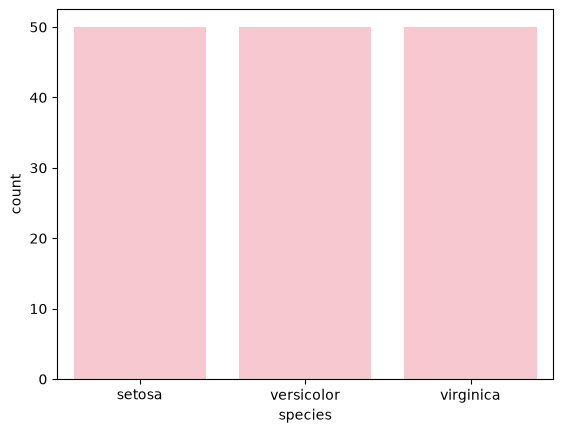

In [4]:
sns.countplot(x=df["species"],color="pink")

In [5]:
X=df.drop(columns=["species"])
y=df["species"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,stratify=y)

In [6]:
model_LR=LogisticRegression()
model_DT=DecisionTreeClassifier()
preprocessor=ColumnTransformer(transformers=[
    ("Scaling",StandardScaler(),list(X.columns))
])


In [7]:
X_train_preprocessed=preprocessor.fit_transform(X_train)
X_test_preprocessed=preprocessor.transform(X_test)

In [8]:
# 1. Train (fit) both models using the preprocessed training data
model_LR.fit(X_train_preprocessed, y_train)
model_DT.fit(X_train_preprocessed, y_train)

# 2. Make predictions on the test set
y_pred_lr = model_LR.predict(X_test_preprocessed)
y_pred_dt = model_DT.predict(X_test_preprocessed)

# 3. Evaluate Logistic Regression
print("--- Logistic Regression Performance ---")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

# 4. Evaluate Decision Tree
print("\n--- Decision Tree Performance ---")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n", classification_report(y_test, y_pred_dt))

--- Logistic Regression Performance ---
Accuracy: 0.9736842105263158

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       0.93      1.00      0.96        13
   virginica       1.00      0.92      0.96        12

    accuracy                           0.97        38
   macro avg       0.98      0.97      0.97        38
weighted avg       0.98      0.97      0.97        38


--- Decision Tree Performance ---
Accuracy: 0.9210526315789473

Classification Report:
               precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       0.92      0.85      0.88        13
   virginica       0.85      0.92      0.88        12

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



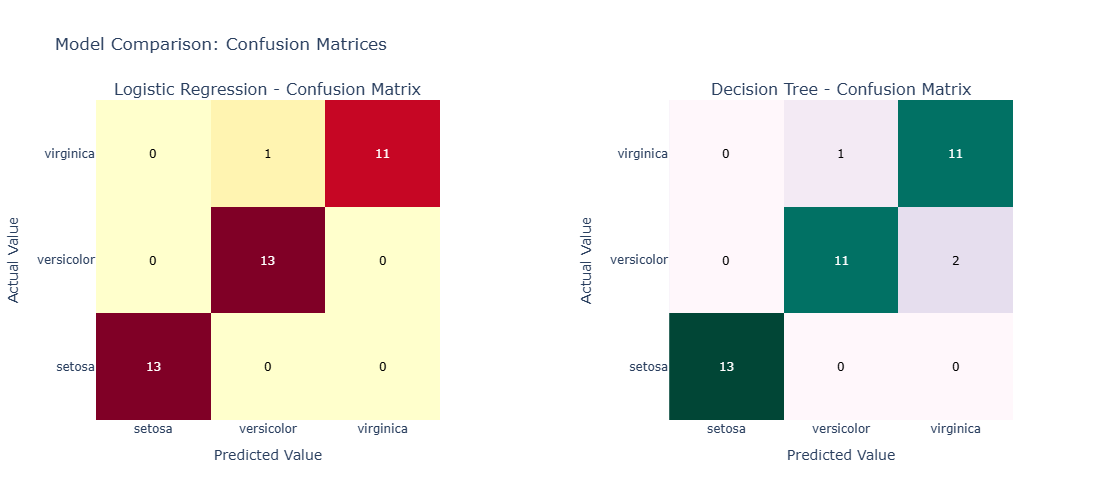

In [21]:
from plotly.subplots import make_subplots
import plotly.figure_factory as ff
from sklearn.metrics import confusion_matrix

# 1. Compute confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_dt = confusion_matrix(y_test, y_pred_dt)
labels = sorted(y_test.unique())

# 2. Create subplots with breathing room in between (horizontal_spacing)
fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Logistic Regression - Confusion Matrix",
        "Decision Tree - Confusion Matrix",
    ),
    horizontal_spacing=0.25,
)

# 3. Generate individual annotated heatmaps
fig_lr = ff.create_annotated_heatmap(
    z=cm_lr, x=labels, y=labels, colorscale="Oranges", showscale=False
)
fig_dt = ff.create_annotated_heatmap(
    z=cm_dt, x=labels, y=labels, colorscale="PuBuGn", showscale=False
)

# 4. Add heatmap data traces to respective subplots
fig.add_trace(fig_lr.data[0], row=1, col=1)
fig.add_trace(fig_dt.data[0], row=1, col=2)

# 5. Correctly map the text annotations to Left Subplot (x1, y1)
for ann in fig_lr.layout.annotations:
  ann.update(xref="x1", yref="y1")
  fig.add_annotation(ann)

# 6. Correctly map the text annotations to Right Subplot (x2, y2)
for ann in fig_dt.layout.annotations:
  ann.update(xref="x2", yref="y2")
  fig.add_annotation(ann)

# 7. Update axes and layout size
fig.update_xaxes(title_text="Predicted Value", row=1, col=1)
fig.update_xaxes(title_text="Predicted Value", row=1, col=2)
fig.update_yaxes(title_text="Actual Value", row=1, col=1)
fig.update_yaxes(title_text="Actual Value", row=1, col=2)

fig.update_layout(
    title_text="Model Comparison: Confusion Matrices", width=1050, height=500
)

fig.show()

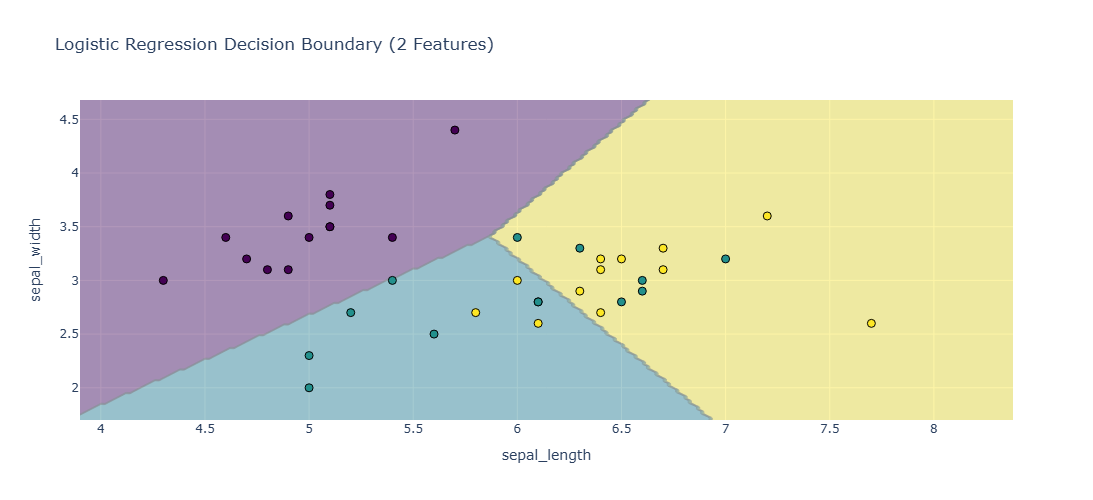

In [10]:
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from sklearn.linear_model import LogisticRegression

# 1. For visualization simplicity, let's pick 2 features (e.g., Sepal Length and Sepal Width)
# If X_train is a DataFrame:
X_train_2d = X_train.iloc[:, :2]
X_test_2d = X_test.iloc[:, :2]

# Train a 2D Logistic Regression model just for the boundary plot
clf_2d = LogisticRegression()
clf_2d.fit(X_train_2d, y_train)

# 2. Create a mesh grid
x_min, x_max = X_train_2d.iloc[:, 0].min() - 0.5, X_train_2d.iloc[:, 0].max() + 0.5
y_min, y_max = X_train_2d.iloc[:, 1].min() - 0.5, X_train_2d.iloc[:, 1].max() + 0.5
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02), np.arange(y_min, y_max, 0.02)
)

# Predict across the grid
Z = clf_2d.predict(np.c_[xx.ravel(), yy.ravel()])
# Convert string labels to numeric for contour plotting if needed, or map them
# For iris, classes are text so let's use a LabelEncoder if they are strings,
# or if y is numeric, Plotly handles it easily. Let's map string labels to integers:
label_mapping = {label: i for i, label in enumerate(np.unique(y_train))}
Z_num = np.array([label_mapping[val] for val in Z])
Z_num = Z_num.reshape(xx.shape)

# 3. Build Plotly Contour + Scatter Plot
fig = go.Figure()

# Add decision boundary contour
fig.add_trace(
    go.Contour(
        x=np.arange(x_min, x_max, 0.02),
        y=np.arange(y_min, y_max, 0.02),
        z=Z_num,
        showscale=False,
        opacity=0.4,
        colorscale="Viridis",
    )
)

# Add actual test data points
y_test_num = [label_mapping[val] for val in y_test]
fig.add_trace(
    go.Scatter(
        x=X_test_2d.iloc[:, 0],
        y=X_test_2d.iloc[:, 1],
        mode="markers",
        marker=dict(
            color=y_test_num, colorscale="Viridis", size=8, line=dict(width=1, color="black")
        ),
        text=y_test,
        name="Test Data",
    )
)

fig.update_layout(
    title="Logistic Regression Decision Boundary (2 Features)",
    xaxis_title=X_train_2d.columns[0],
    yaxis_title=X_train_2d.columns[1],
    width=700,
    height=500,
)
fig.show()